In [9]:
from trueml.datasets import load_diabetes

df = load_diabetes()

X = df.data
y = df.target.reshape(-1, 1)

print("X:", X.shape, "y:", y.shape)

X: (442, 10) y: (442, 1)


In [25]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


X_scaled

array([[ 0.80050009,  1.06548848,  1.29708846, ..., -0.05449919,
         0.41853093, -0.37098854],
       [-0.03956713, -0.93853666, -1.08218016, ..., -0.83030083,
        -1.43658851, -1.93847913],
       [ 1.79330681,  1.06548848,  0.93453324, ..., -0.05449919,
         0.06015558, -0.54515416],
       ...,
       [ 0.87686984,  1.06548848, -0.33441002, ..., -0.23293356,
        -0.98564884,  0.32567395],
       [-0.9560041 , -0.93853666,  0.82123474, ...,  0.55838411,
         0.93616291, -0.54515416],
       [-0.9560041 , -0.93853666, -1.53537419, ..., -0.83030083,
        -0.08875225,  0.06442552]], shape=(442, 10))

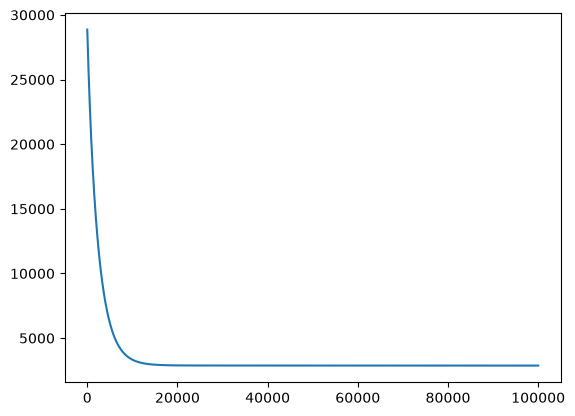

In [39]:
from trueml.linear_model import LinearModel
from trueml.losses import MSELoss

n_features = X.shape[1]
n_targets = y.shape[1]
epochs = 100000

model = LinearModel(n_features=n_features, n_targets=n_targets, lr = 0.0001, history=True)
loss_fn = MSELoss()

for epoch in range(epochs):
    y_pred = model.forward(X_scaled)
    dL_dy_pred = loss_fn.grad(y, y_pred)
    model.backward(dL_dy_pred)
    model.history.append(epoch, loss=loss_fn(y, y_pred))

import matplotlib.pyplot as plt

plt.plot(model.history["loss"])
plt.show()

In [34]:
print("w:", model.weights, "\n\nb:", model.bias)

w: [[ -0.32958093]
 [-11.25142846]
 [ 25.11392714]
 [ 15.31234497]
 [ -7.20712469]
 [ -1.80989471]
 [ -8.46209367]
 [  5.13225198]
 [ 24.21962509]
 [  3.31715556]] 

b: [152.13348386]


In [44]:
from trueml.linear_model import LinearRegression

model = LinearRegression(X_scaled, y, lr=0.001)
model.train(loss_fn=loss_fn, epochs=10000)

100%|████████████████████████████████| 10000/10000 [00:00<00:00, GFLOPs=1.35, loss=2875.3288]


In [ ]:
print("w:", model.weights, "\n\nb:", model.bias)